# 04 — Model Comparison

ROC AUC / precision / recall per model on the same time-based test split
as `main.py`, feature importances, probability calibration, and error
analysis by ticker and by month. The LSTM runs only if TensorFlow is
installed (it is an optional dependency -- see README).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import data as data_mod
from src import features as feat_mod
from src import models as models_mod
from src import simulate as sim_mod
from src.target import make_target, time_split

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (10, 5)

from src import lstm_model as lstm_mod

# Same parameters as the fuller main.py run (50 tickers, 5 years).
# Downloads are cached under data/ (7-day freshness), so re-running is fast.
tickers = data_mod.get_universe(n=50)
prices = data_mod.download_prices(tickers, years=5)
macro = data_mod.download_macro(years=5)
french = data_mod.download_french_weekly()
spy = data_mod.download_benchmark(years=5)

feat = feat_mod.build_features(prices, macro=macro, french=french)
panel = make_target(feat)
numeric, dummies = feat_mod.feature_columns(panel)
feature_cols = numeric + dummies
train, test, cutoff = time_split(panel, train_frac=0.7)
print(f"Cutoff: {cutoff.date()}")

I0000 00:00:1795570421.784921   18090 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795570426.106475   18090 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Universe: 503 tickers from Wikipedia S&P 500 list.
Prices: using cache /home/hatch/workspace/stock-markets-analytics-project/data/prices_weekly.parquet
Macro: using cache /home/hatch/workspace/stock-markets-analytics-project/data/macro_weekly.parquet
French factors: using cache /home/hatch/workspace/stock-markets-analytics-project/data/french_weekly.parquet
Benchmark: using cache /home/hatch/workspace/stock-markets-analytics-project/data/spy_weekly.parquet


Features: 10,550 rows after dropping 2,550 incomplete rows; 50 tickers, 211 weeks.
Target: 10,500 rows, positive rate 0.200 (expected ~0.20).
Time split: train 2022-11-14 -> 2025-09-01 (7,350 rows); test 2025-09-08 -> 2026-11-16 (3,150 rows).
Cutoff: 2025-09-08


## Train the models

In [2]:
from sklearn.metrics import roc_auc_score

scores = {}   # name -> test scores
rf = models_mod.train_random_forest(train[feature_cols], train['target'])
scores['RandomForest'] = models_mod.score_random_forest(rf, test[feature_cols])
ff = models_mod.train_factor_regression(train[feature_cols], train['next_ret'])
scores['FF-regression'] = models_mod.score_factor_regression(ff, test[feature_cols])
if models_mod.xgboost_available():
    xgb = models_mod.train_xgboost(train[feature_cols], train['target'])
    scores['XGBoost'] = models_mod.score_xgboost(xgb, test[feature_cols])
else:
    print("XGBoost not installed, skipping.")

# LSTM (optional): sequences from the full panel, same cutoff split.
lstm_meta = None
if lstm_mod.tensorflow_available():
    X_seq, y_seq, meta = lstm_mod.build_sequences(panel, feature_cols)
    te = (pd.to_datetime(meta['date']) >= cutoff).to_numpy()
    tr = ~te
    lstm, scaler, _, _ = lstm_mod.train_lstm(
        X_seq[tr], y_seq[tr], meta.loc[tr, 'date'])
    lstm_meta = meta[te].copy()
    lstm_meta['score'] = lstm_mod.score_lstm(lstm, scaler, X_seq[te])
    scores['LSTM'] = None  # scored on meta rows, handled separately below
    print(f"LSTM test rows: {len(lstm_meta)}")
else:
    print("TensorFlow not installed -- LSTM skipped (see README).")

LSTM sequences: 9,950 sequences, shape (9950, 12, 31), positive rate 0.200


LSTM trained: 7 epochs, val AUC 0.502


LSTM test rows: 3150


## ROC AUC / precision / recall

In [3]:
from sklearn.metrics import precision_score, recall_score

rows = []
for name, s in scores.items():
    if s is None:
        continue
    y_pred = (s >= 0.5).astype(int)
    rows.append({'model': name,
                 'roc_auc': roc_auc_score(test['target'], s),
                 'precision@0.5': precision_score(test['target'], y_pred, zero_division=0),
                 'recall@0.5': recall_score(test['target'], y_pred, zero_division=0)})
if lstm_meta is not None:
    s = lstm_meta['score'].to_numpy()
    y_pred = (s >= 0.5).astype(int)
    rows.append({'model': 'LSTM',
                 'roc_auc': roc_auc_score(lstm_meta['target'], s),
                 'precision@0.5': precision_score(lstm_meta['target'], y_pred, zero_division=0),
                 'recall@0.5': recall_score(lstm_meta['target'], y_pred, zero_division=0)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

        model  roc_auc  precision@0.5  recall@0.5
 RandomForest    0.604          0.417       0.008
FF-regression    0.589          0.000       0.000
      XGBoost    0.593          0.348       0.013
         LSTM    0.595          0.242       0.625


## Feature importances (RF + XGBoost)

RandomForest top 15:
vol_12w          0.078
dist_52w_low     0.065
vol_4w           0.064
dist_52w_high    0.060
ret_12w          0.059
rsi_14           0.059
ret_1w           0.057
ret_4w           0.056
macd_signal      0.054
macd_hist        0.054
vol_ratio_4w     0.053
macd             0.052
mkt_rf           0.038
hml              0.035
tnx              0.035
dtype: float64


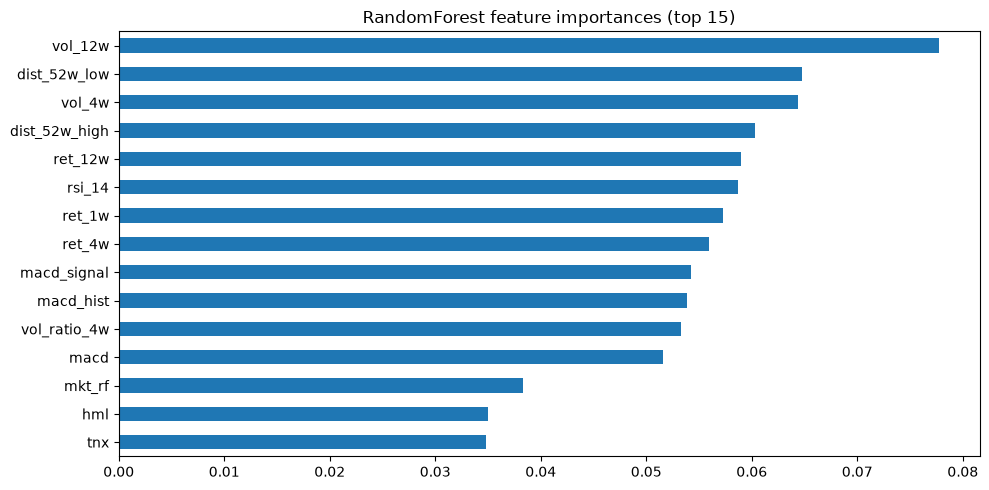

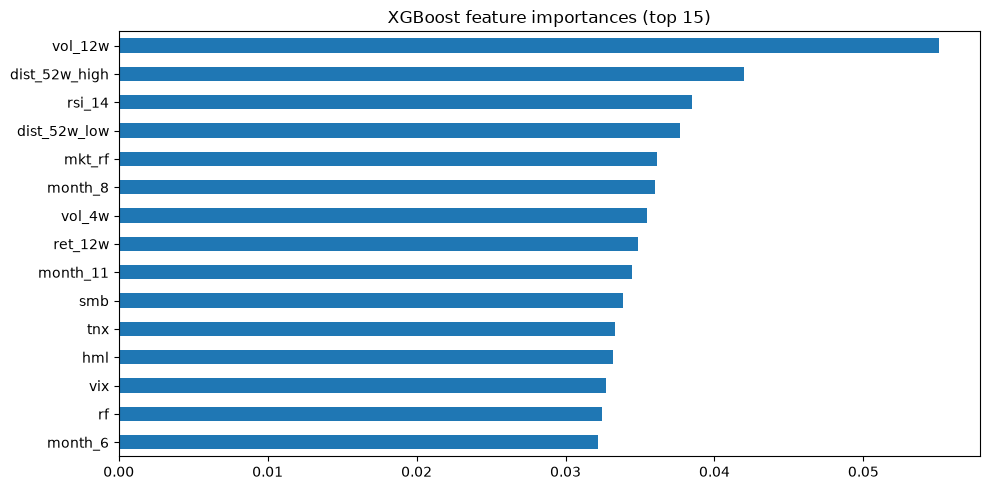

In [4]:
imp = pd.Series(rf.feature_importances_, index=feature_cols)
print("RandomForest top 15:")
print(imp.sort_values(ascending=False).head(15).round(3))
fig, ax = plt.subplots()
imp.sort_values(ascending=False).head(15).sort_values().plot.barh(ax=ax)
ax.set_title('RandomForest feature importances (top 15)')
plt.tight_layout()
plt.show()
if models_mod.xgboost_available():
    imp_x = pd.Series(xgb.feature_importances_, index=feature_cols)
    fig, ax = plt.subplots()
    imp_x.sort_values(ascending=False).head(15).sort_values().plot.barh(ax=ax)
    ax.set_title('XGBoost feature importances (top 15)')
    plt.tight_layout()
    plt.show()

## Calibration of predicted probabilities

Bin the test rows by predicted probability decile and compare the mean
predicted probability with the actual positive rate in each bin. A
well-calibrated model tracks the diagonal; systematic gaps mean the
probabilities should not be read literally (ranking still works).

     mean_pred  actual_rate    n
bin                             
0        0.126        0.137  315
1        0.148        0.143  315
2        0.162        0.159  315
3        0.175        0.146  315
4        0.191        0.213  315
5        0.213        0.133  315
6        0.242        0.206  315
7        0.280        0.270  315
8        0.325        0.254  315
9        0.407        0.340  315


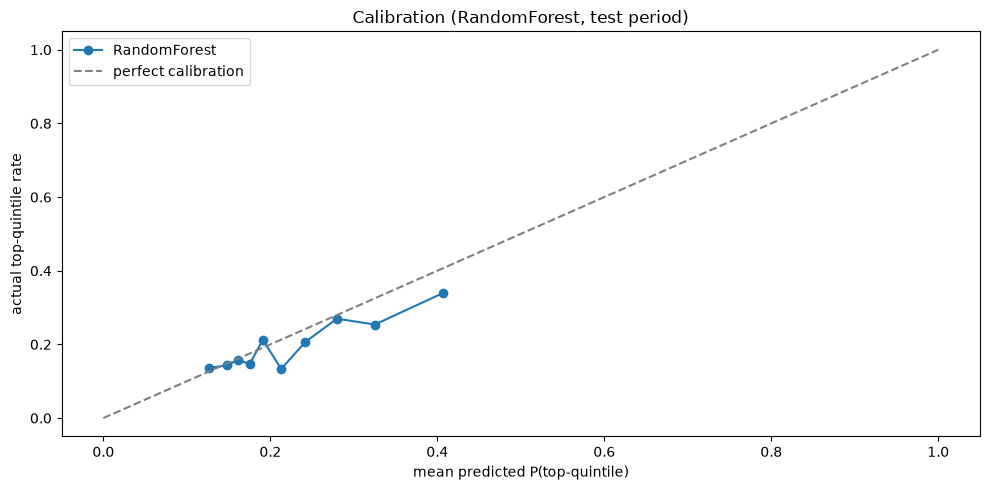

In [5]:
cal = test[['target']].copy()
cal['score'] = scores['RandomForest']
cal['bin'] = pd.qcut(cal['score'], 10, labels=False, duplicates='drop')
g = cal.groupby('bin').agg(mean_pred=('score', 'mean'),
                           actual_rate=('target', 'mean'),
                           n=('target', 'size'))
print(g.round(3))
fig, ax = plt.subplots()
ax.plot(g['mean_pred'], g['actual_rate'], marker='o', label='RandomForest')
ax.plot([0, 1], [0, 1], '--', color='grey', label='perfect calibration')
ax.set_xlabel('mean predicted P(top-quintile)')
ax.set_ylabel('actual top-quintile rate')
ax.set_title('Calibration (RandomForest, test period)')
ax.legend()
plt.tight_layout()
plt.show()

## Error analysis: by ticker and by month

In [6]:
test_rf = test.copy()
test_rf['score'] = scores['RandomForest']
# Per-ticker AUC (test rows only, min 15 rows to be meaningful).
aucs = []
for t, g in test_rf.groupby('ticker'):
    if len(g) >= 15 and g['target'].nunique() > 1:
        aucs.append((t, len(g), roc_auc_score(g['target'], g['score'])))
aucs = pd.DataFrame(aucs, columns=['ticker', 'n', 'auc']).sort_values('auc')
print("Worst 5 tickers by test AUC:")
print(aucs.head(5).round(3).to_string(index=False))
print("\nBest 5 tickers by test AUC:")
print(aucs.tail(5).round(3).to_string(index=False))
test_rf['month'] = pd.to_datetime(test_rf['date']).dt.month
bym = test_rf.groupby('month').apply(
    lambda g: roc_auc_score(g['target'], g['score'])
    if g['target'].nunique() > 1 else np.nan, include_groups=False)
print("\nTest AUC by calendar month:")
print(bym.round(3))

Worst 5 tickers by test AUC:
ticker  n   auc
   AES 63 0.227
  AMCR 63 0.274
   AXP 63 0.295
  ABNB 63 0.305
   AFL 63 0.339

Best 5 tickers by test AUC:
ticker  n   auc
   ADM 63 0.657
   ABT 63 0.658
   ACN 63 0.663
   AWK 63 0.687
  ADBE 63 0.718

Test AUC by calendar month:
month
1     0.539
2     0.565
3     0.569
4     0.715
5     0.546
6     0.606
7     0.563
8     0.616
9     0.593
10    0.571
11    0.665
12    0.704
dtype: float64
